In [1]:
from typing import TypedDict, Annotated
from dotenv import load_dotenv
import requests
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage
from IPython.display import Image, display
import os
load_dotenv()

True

In [2]:
# Below code is only for testing to validate your github key
GITHUB_TOKEN = os.getenv("GITHUB_TOKEN")

GITHUB_REPO  = "rahul8879/e-comm-agentic-demo"

HEADERS = {
    "Accept": "application/vnd.github+json",
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "X-GitHub-Api-Version": "2022-11-28",
}

BASE_URL = f"https://api.github.com/repos/{GITHUB_REPO}"

r = requests.get(
    BASE_URL, headers=HEADERS
)


# r.status_code
# r.json()

In [3]:
PR_NUMBER=11

In [4]:
@tool
def get_pr_details():
    """Fetch the full content of a file from the repo's default branch."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}"
    r = requests.get(url, headers=HEADERS)

    pr = r.json()
    return {
        "title":       pr.get("title"),
        "description": pr.get("body", "No description provided"),
        "author":      pr["user"]["login"],
        "state":       pr.get("state"),
        "branch":      pr["head"]["ref"],
    }


@tool
def get_pr_files() -> list:
    """List all files changed in the PR with their status and patch."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}/files"
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    files = []
    for f in r.json():
        files.append({
            "filename": f.get("filename"),
            "status":   f.get("status"),       # added / modified / removed
            "changes":  f.get("changes"),
            "patch":    f.get("patch", "")[:4000],  # limit patch size
        })
    return files

import base64

@tool
def get_file_content(file_path: str) -> str:
    """Fetch the full content of a file from the repo's default branch."""
    url = f"{BASE_URL}/contents/{file_path}"
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    data = r.json()
    if "content" not in data:
        return f"Could not fetch: {file_path}"
    return base64.b64decode(data["content"]).decode("utf-8")

@tool
def post_pr_comment(comment: str) -> dict:
    """Post a review comment on the PR."""
    print('recommended by llm', comment)
    url = f"{BASE_URL}/issues/{PR_NUMBER}/comments"
    payload = {"body": comment}
    r = requests.post(url, headers=HEADERS, json=payload, timeout=30)
    r.raise_for_status()
    return {"status": r.status_code, "comment_url": r.json().get("html_url")}




tools = [get_pr_details, get_pr_files, get_file_content, post_pr_comment]

In [ ]:
# step 1 : Define your agent's state

class State(TypedDict):
    messages : Annotated[list, add_messages]
    pr_number : int



llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
llm_with_tools = llm.bind_tools(tools)

In [6]:
SYSTEM_PROMPT = """You are CodeSentinel — an expert PR code reviewer.

Always post a comment in this format on github page:
## 🤖 CodeSentinel Review
### ✅ What looks good
- ...

### ⚠️ Issues Found
- ...

### 🔧 Suggestions
- ...

### 📊 Verdict
APPROVED / NEEDS CHANGES

You are free to post comment in PR : use tool post_pr_comment
"""

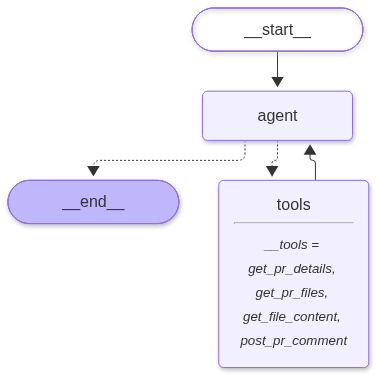

In [7]:

# step 2 : Define your node
def agent_node(state: State):
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}



def should_continue(state: State):
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END


tool_node = ToolNode(tools)



# step 3 : Convert your python function into node

graph_builder = StateGraph(State)
graph_builder.add_node("agent", agent_node)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "agent") 

graph_builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)



graph_builder.add_edge("tools", "agent") 
graph = graph_builder.compile()
graph


In [8]:
PR_NUMBER = 14

initial_state = {
    "messages": [
        HumanMessage(
            content=f"Review PR #{PR_NUMBER}"
        )
    ],
    "pr_number": PR_NUMBER,
    "verdict":   "",
}

result = graph.invoke(initial_state)

In [9]:
result

{'messages': [HumanMessage(content='Review PR #14', additional_kwargs={}, response_metadata={}, id='448e0593-1fba-484d-9f7e-c477d22e87d0'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 209, 'total_tokens': 250, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_27b52db0fd', 'id': 'chatcmpl-EgtmOmRMvSKXoL49exWwLQS7WvLeH', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1ac59-56f4-76f6-a13a-233aab5f3bda-0', tool_calls=[{'name': 'get_pr_details', 'args': {}, 'id': 'call_HSL0IoEHL6AcH004EmTmlpRS', 'type': 'tool_call'}, {'name

In [10]:
post_pr_comment.invoke("testing")

recommended by llm testing


{'status': 201,
 'comment_url': 'https://github.com/rahul8879/e-comm-agentic-demo/pull/14#issuecomment-6662097837'}

In [11]:
print(result["messages"][-1].content)

## 🤖 CodeSentinel Review
### ✅ What looks good
- The PR is concise and focuses on a single change, which is good for maintainability and reviewability.
- The author has provided a clear title and description for the PR.

### ⚠️ Issues Found
- The change in `orders.py` appears to be a comment addition that doesn't contribute to functionality. This might not be necessary unless it's for documentation purposes.

### 🔧 Suggestions
- If the comment added in `orders.py` is meant for documentation, consider expanding it to provide more context or remove it if it's not needed.
- Ensure that any dummy code or comments added are relevant and necessary for the codebase to avoid clutter.

### 📊 Verdict
NEEDS CHANGES
